## **Loan Approval Predictor**
#### Life cycle of a Machine Learning Project
- Understanding the problem statement
- Data collection
- Data Checks to perform
- Exploratory data analysis
- Data Pre-Processing
- Model Training
- Choose best model

### **1) Problem Statement:**
- This projects understands how customer's loan application gets approved based on several factors such as Gender, Marital status, Dependents, Education, Employment, Income, Loan amount, credit history, property area.


### **2) Data collection:**
- this dataset is sourced from kaggle
- it consists of 614 rows and 13 columns.

### **3) Importing libraries required:**

In [ ]:
# importing libraries and dataset
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [ ]:

df = pd.read_csv("/content/Loan_dataset (1).csv")
df.head()

,Loan_ID,Gender,Married,Dependents,Education,Self_Employed,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History,Property_Area,Loan_Status
0,LP001002,Male,No,0,Graduate,No,5849,0.0,NaN,360.0,1.0,Urban,Y
1,LP001003,Male,Yes,1,Graduate,No,4583,1508.0,128.0,360.0,1.0,Rural,N
2,LP001005,Male,Yes,0,Graduate,Yes,3000,0.0,66.0,360.0,1.0,Urban,Y
3,LP001006,Male,Yes,0,Not Graduate,No,2583,2358.0,120.0,360.0,1.0,Urban,Y
4,LP001008,Male,No,0,Graduate,No,6000,0.0,141.0,360.0,1.0,Urban,Y


In [ ]:
df.shape

(614, 13)

### **5) Dataset Information:**
- Loan ID
- Gender- Male / Female
-

### **5) Data Checks to perform:**
- Check Missing values
- Check Duplicates
- Check data type
- Check the number of unique values of each column
- Check statistics of data set
- Check various categories present in the different categorical column

#### **5.1) Checking for missing values:**

In [ ]:
df.isna().sum()

,0
Loan_ID,0
Gender,13
Married,3
Dependents,15
Education,0
Self_Employed,32
ApplicantIncome,0
CoapplicantIncome,0
LoanAmount,22
Loan_Amount_Term,14


##### **Missing Values**
- 13 missing in Gender
- 3 missing in Married
- 15 missing in Dependents
- 32 missing in Self_employed
- 22 missing in LoanAmount
- 50 missing in Credit_History

In [ ]:
# check for data type:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 614 entries, 0 to 613
Data columns (total 13 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Loan_ID            614 non-null    object 
 1   Gender             601 non-null    object 
 2   Married            611 non-null    object 
 3   Dependents         599 non-null    object 
 4   Education          614 non-null    object 
 5   Self_Employed      582 non-null    object 
 6   ApplicantIncome    614 non-null    int64  
 7   CoapplicantIncome  614 non-null    float64
 8   LoanAmount         592 non-null    float64
 9   Loan_Amount_Term   600 non-null    float64
 10  Credit_History     564 non-null    float64
 11  Property_Area      614 non-null    object 
 12  Loan_Status        614 non-null    object 
dtypes: float64(4), int64(1), object(8)
memory usage: 62.5+ KB


In [ ]:
df.nunique()

,0
Loan_ID,614
Gender,2
Married,2
Dependents,4
Education,2
Self_Employed,2
ApplicantIncome,505
CoapplicantIncome,287
LoanAmount,203
Loan_Amount_Term,10


In [ ]:
df.Credit_History.value_counts()

,count
Credit_History,
1.0,475
0.0,89


In [ ]:
df.Loan_Status.value_counts()
# imbalanced dataset

,count
Loan_Status,
Y,422
N,192


In [ ]:
# Loan Id not relevant for problem statement
df = df.drop(columns = ['Loan_ID'])

In [ ]:
# imputing missing values
df.Gender.fillna(df.Gender.mode()[0], inplace = True)
df.Married.fillna(df.Married.mode()[0], inplace = True)

/tmp/ipython-input-11-3793593405.py:2: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df.Gender.fillna(df.Gender.mode()[0], inplace = True)
/tmp/ipython-input-11-3793593405.py:3: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=Tru

In [ ]:
df.isna().sum()

,0
Gender,0
Married,0
Dependents,15
Education,0
Self_Employed,32
ApplicantIncome,0
CoapplicantIncome,0
LoanAmount,22
Loan_Amount_Term,14
Credit_History,50


In [ ]:
# Checking duplicates in the dataset
df.duplicated().sum()

np.int64(0)

**There are no duplicates in the dataset**





<Axes: xlabel='Dependents'>

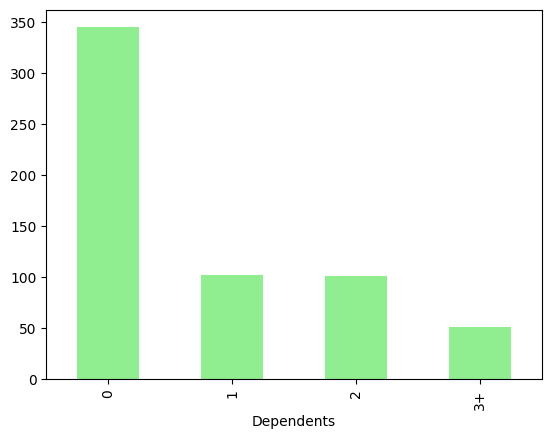

In [ ]:
df.Dependents.value_counts().plot(kind = 'bar', color = 'lightgreen')

In [ ]:
df.Dependents.value_counts()

,count
Dependents,
0,345
1,102
2,101
3+,51


# imputing values proprotion wise

In [ ]:
proportion = df.Dependents.value_counts(normalize = True).to_list()
missing_indices = df[df.Dependents.isna()].index
imputed_values = np.random.choice(df.Dependents.unique()[0:4], size = len(missing_indices), p = proportion)
df.loc[missing_indices, 'Dependents'] = imputed_values


In [ ]:
proportion = df['Self_Employed'].value_counts(normalize = True).to_list()
missing_indices = df[df.Self_Employed.isna()].index
n = len(df['Self_Employed'].unique())
imputed_values = np.random.choice(df['Self_Employed'].unique()[0:n-1], size = len(missing_indices), p = proportion)
df.loc[missing_indices, 'Self_Employed'] = imputed_values

In [ ]:
df.isna().sum()

,0
Gender,0
Married,0
Dependents,0
Education,0
Self_Employed,0
ApplicantIncome,0
CoapplicantIncome,0
LoanAmount,22
Loan_Amount_Term,14
Credit_History,50


 we can impute Loan Amount and credit history using Naive Bayes

<Axes: xlabel='LoanAmount', ylabel='Count'>

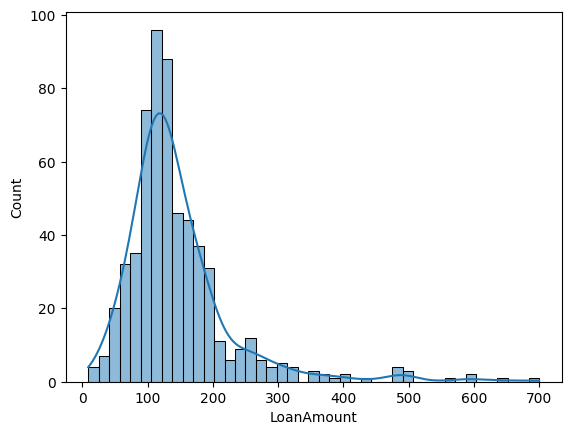

In [ ]:
sns.histplot(df.LoanAmount, kde = True) # Loan Amount ko KNN impute kr skte hai

<Axes: xlabel='Loan_Amount_Term', ylabel='LoanAmount'>

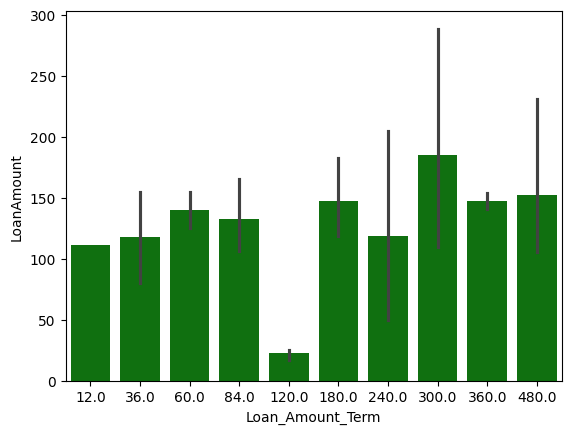

In [ ]:
sns.barplot(x = df.Loan_Amount_Term, y = df.LoanAmount, color = 'g')

<Axes: xlabel='ApplicantIncome', ylabel='Count'>

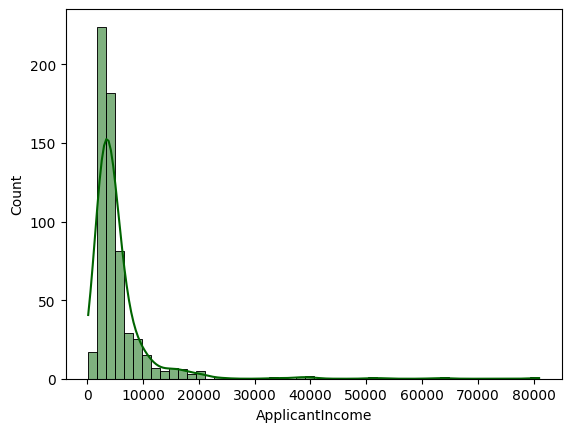

In [ ]:
sns.histplot(df.ApplicantIncome, bins =50, kde = True, color = 'darkgreen')

<Axes: xlabel='CoapplicantIncome', ylabel='Count'>

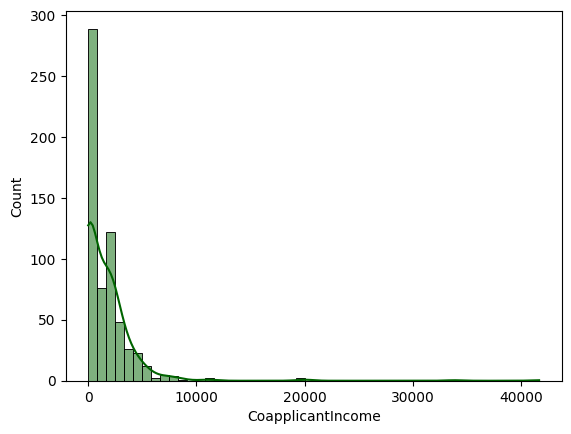

In [ ]:
sns.histplot(df.CoapplicantIncome, bins =50, kde = True, color = 'darkgreen')

In [ ]:
df['TotalIncome'] = df.ApplicantIncome + df.CoapplicantIncome

<Axes: xlabel='Loan_Amount_Term', ylabel='LoanAmount'>

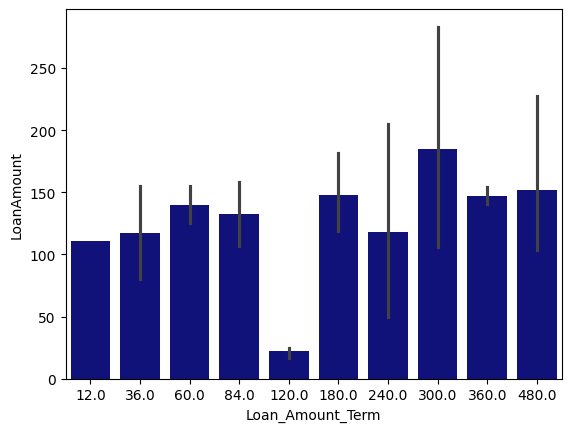

In [ ]:
sns.barplot(x = df.Loan_Amount_Term, y = df.LoanAmount, color = 'darkblue')

<Axes: xlabel='Loan_Amount_Term'>

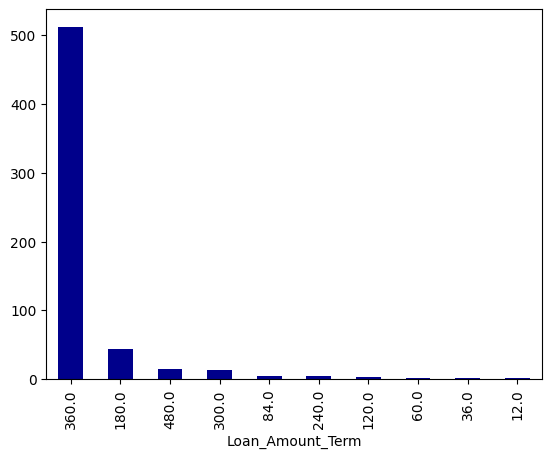

In [ ]:
df.Loan_Amount_Term.value_counts().plot(kind = 'bar', color = 'darkblue')

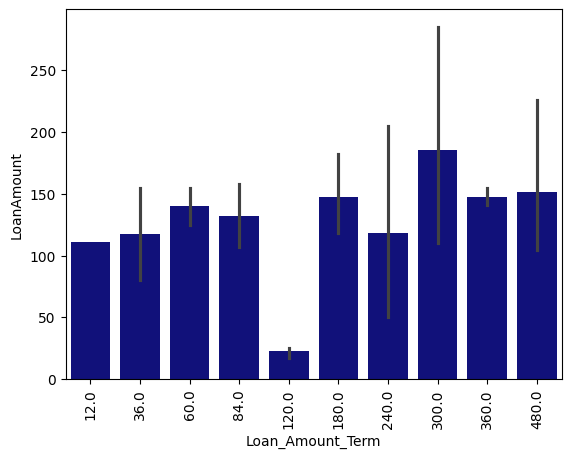

In [ ]:
sns.barplot(x = df.Loan_Amount_Term, y = df.LoanAmount, color = 'darkblue')
plt.xticks(rotation = 'vertical')
plt.show()

### Lets impute Loan AMount, Loan AMount Term and Credit History using Predictive Algorithms

In [ ]:
data = df.dropna()

In [ ]:
data.drop(columns = ['Loan_Status'], inplace = True)

/tmp/ipython-input-28-3378013970.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  data.drop(columns = ['Loan_Status'], inplace = True)


In [ ]:
data.head()

,Gender,Married,Dependents,Education,Self_Employed,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History,Property_Area,TotalIncome
1,Male,Yes,1,Graduate,No,4583,1508.0,128.0,360.0,1.0,Rural,6091.0
2,Male,Yes,0,Graduate,Yes,3000,0.0,66.0,360.0,1.0,Urban,3000.0
3,Male,Yes,0,Not Graduate,No,2583,2358.0,120.0,360.0,1.0,Urban,4941.0
4,Male,No,0,Graduate,No,6000,0.0,141.0,360.0,1.0,Urban,6000.0
5,Male,Yes,2,Graduate,Yes,5417,4196.0,267.0,360.0,1.0,Urban,9613.0


<Axes: xlabel='Gender', ylabel='LoanAmount'>

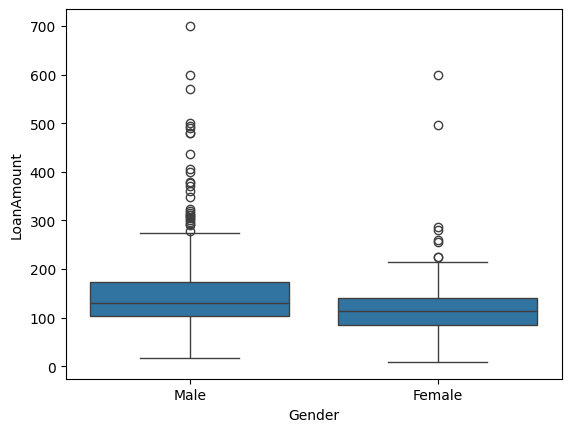

In [ ]:
sns.boxplot(x = data.Gender, y= data.LoanAmount)

In [ ]:
# from scipy.stats import f_oneway
# f_stat, p_value = f_oneway(*grouped_data)
# print(f'F- statistic : {f_stat}')
# print(f'p value: {p_value}')

In [ ]:
(df.shape[0]- data.shape[0])*100/df.shape[0]

13.843648208469055

### **Univariate Analysis:**


In [ ]:
cat_columns = [feature for feature in data.columns if df[feature].dtype == 'object']
for col in cat_columns:
  print(f'Categories in {col} variable:', end = ' ')
  print(data[col].unique())


Categories in Gender variable: ['Male' 'Female']
Categories in Married variable: ['Yes' 'No']
Categories in Dependents variable: ['1' '0' '2' '3+']
Categories in Education variable: ['Graduate' 'Not Graduate']
Categories in Self_Employed variable: ['No' 'Yes']
Categories in Property_Area variable: ['Rural' 'Urban' 'Semiurban']


In [ ]:
num_columns = [feature for feature in df.columns if df[feature].dtype != 'object']
print(f'Categorical features are: {cat_columns}')
print(f'Numerical features are: {num_columns}')

Categorical features are: ['Gender', 'Married', 'Dependents', 'Education', 'Self_Employed', 'Property_Area']
Numerical features are: ['ApplicantIncome', 'CoapplicantIncome', 'LoanAmount', 'Loan_Amount_Term', 'Credit_History', 'TotalIncome']


<Axes: xlabel='Gender'>

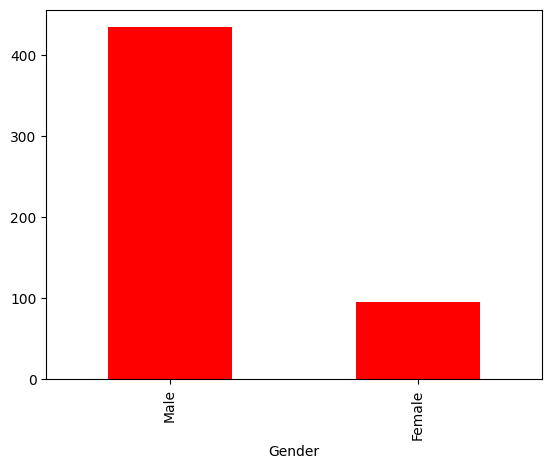

In [ ]:
# 1) Gender:
data.Gender.value_counts().plot(kind = 'bar', color = 'red')

Male customers applies for Loan more than Female customers

<Axes: xlabel='LoanAmount', ylabel='Count'>

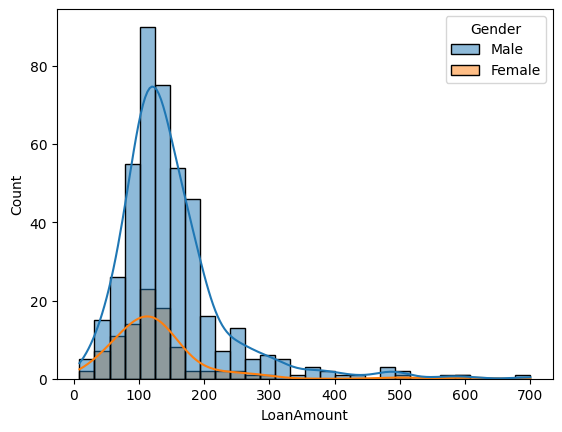

In [ ]:
# Loan amount and Gender relation any :)
sns.histplot(data =  data, x = 'LoanAmount', bins = 30, kde = True, hue = 'Gender')

Males tend to Loan bigger amount than Females.

<Axes: xlabel='LoanAmount', ylabel='Count'>

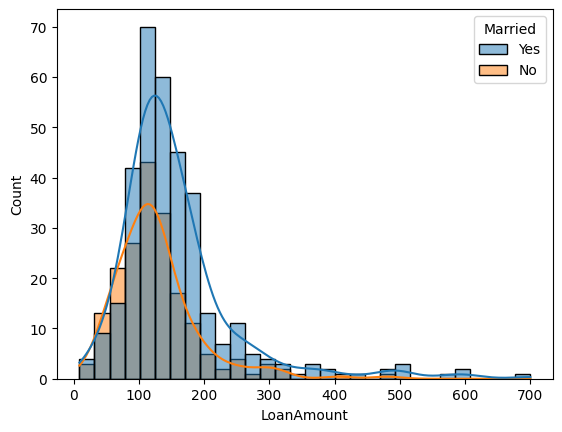

In [ ]:
sns.histplot(data =  data, x = 'LoanAmount', bins = 30, kde = True, hue = 'Married')

Married people take higher Loan amount than Unmarried.

<Axes: xlabel='LoanAmount', ylabel='Count'>

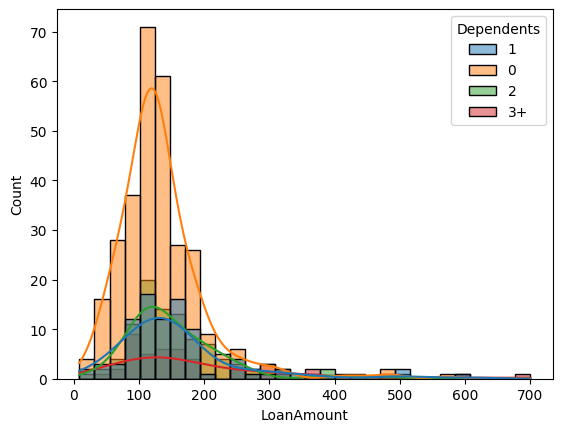

In [ ]:
sns.histplot(data =  data, x = 'LoanAmount', bins = 30, kde = True, hue = 'Dependents')

as dependents increase, Loan amount decreases.

<Axes: xlabel='LoanAmount', ylabel='Count'>

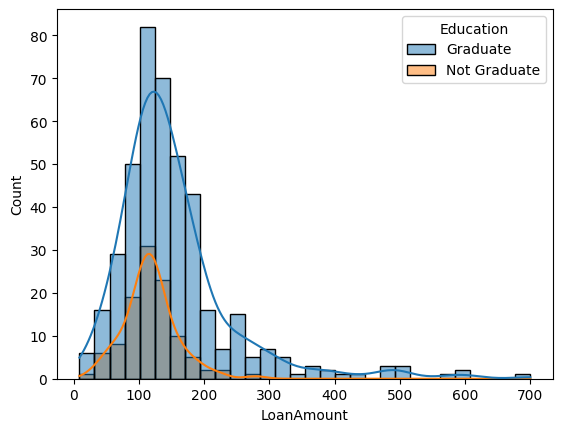

In [ ]:
sns.histplot(data =  data, x = 'LoanAmount', bins = 30, kde = True, hue = 'Education')

<Axes: xlabel='LoanAmount', ylabel='Count'>

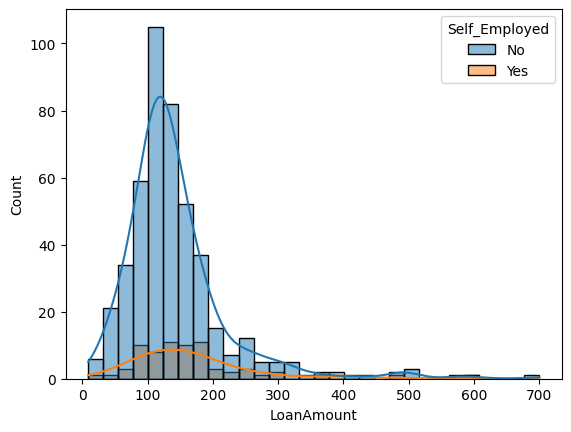

In [ ]:
sns.histplot(data =  data, x = 'LoanAmount', bins = 30, kde = True, hue = 'Self_Employed')

<Axes: xlabel='LoanAmount', ylabel='Count'>

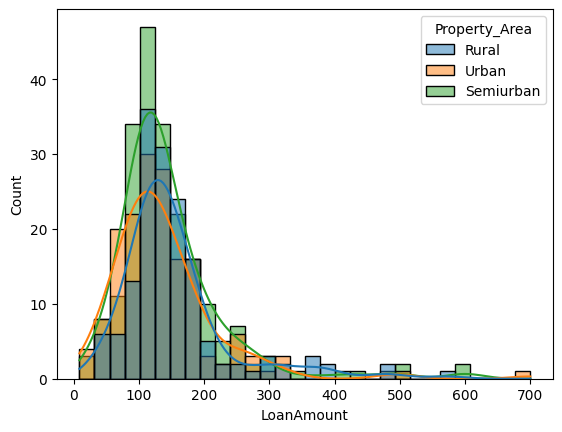

In [ ]:
sns.histplot(data =  data, x = 'LoanAmount', bins = 30, kde = True, hue = 'Property_Area')

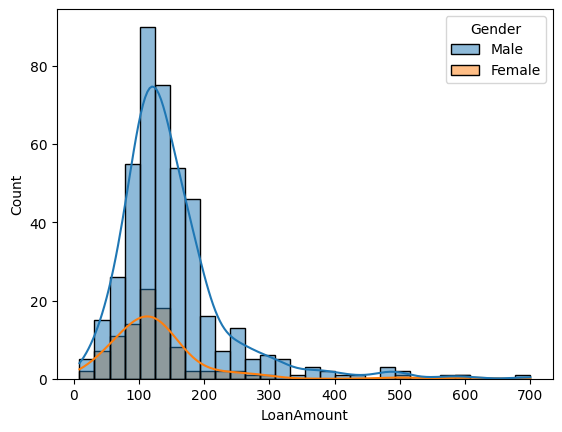

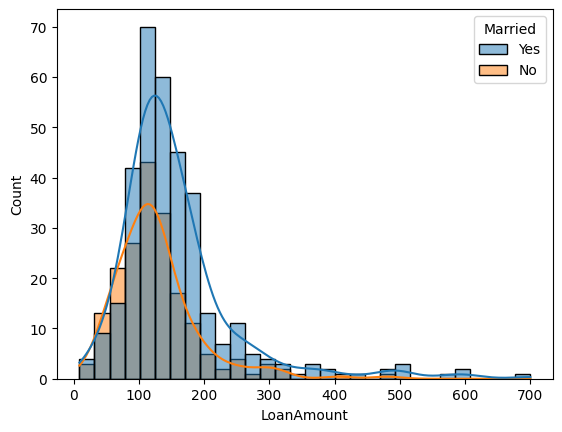

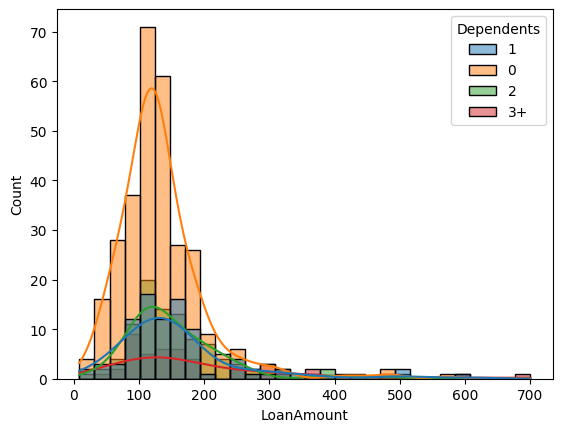

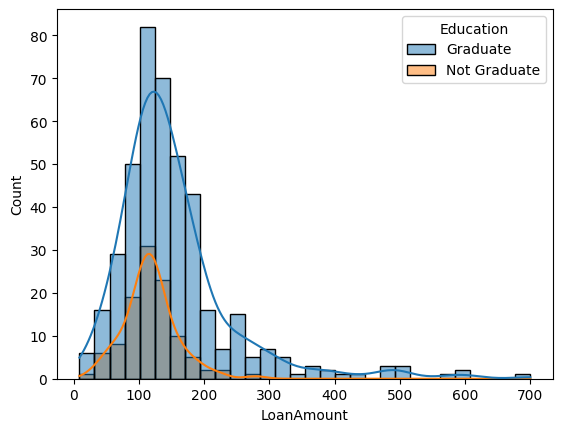

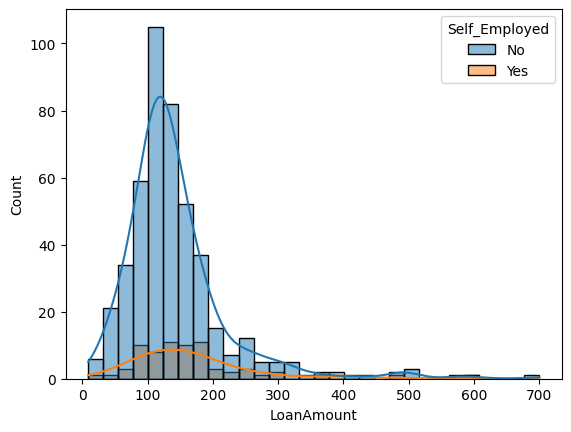

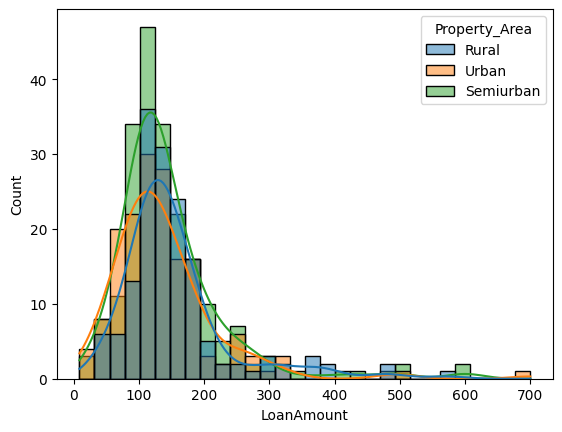

In [ ]:
for col in cat_columns:
  sns.histplot(data =  data, x = 'LoanAmount', bins = 30, kde = True, hue = col)
  plt.show()

### **Interpretation**

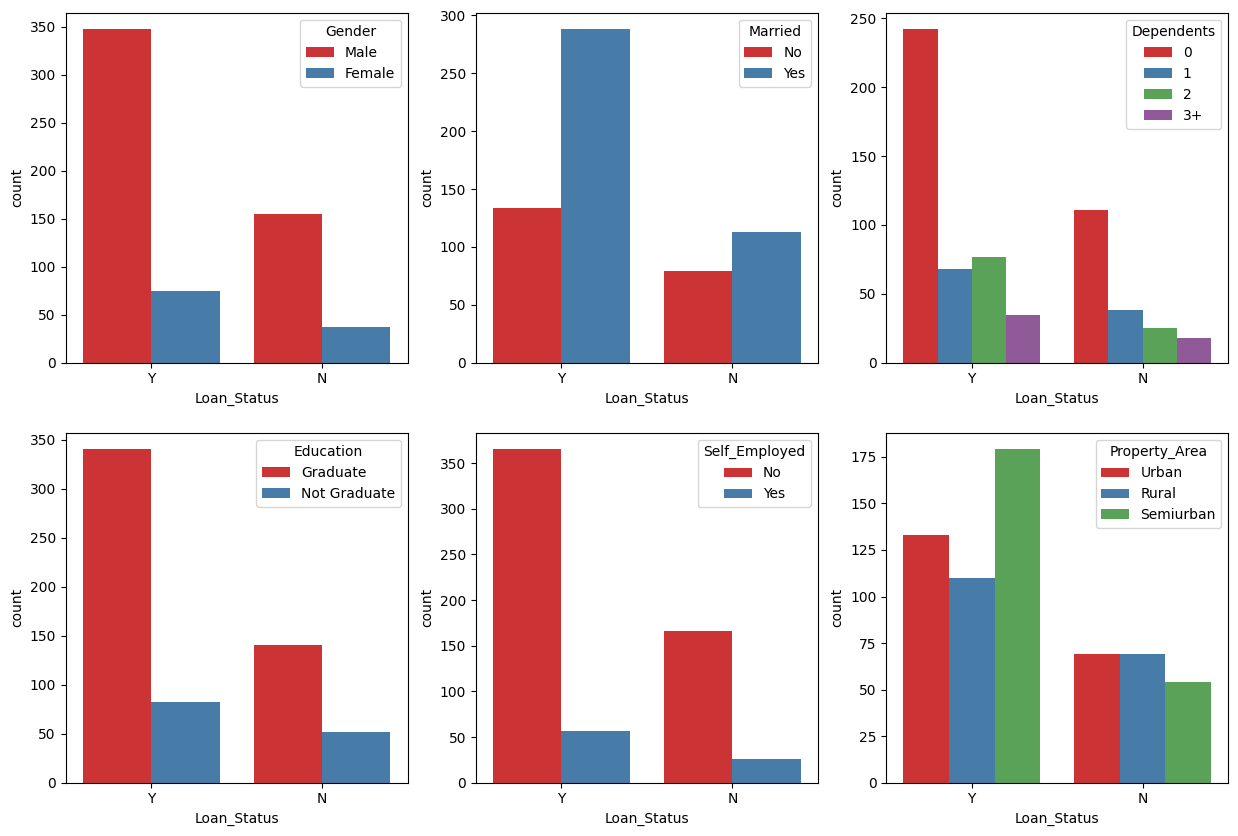

In [ ]:
# cat_columns = [feature for feature in df.columns if df[feature].dtype == 'o']
fig, axes = plt.subplots(2,3,figsize = (15,10))
axes = axes.flatten()
i=0
for col in cat_columns:
  sns.countplot(x = df.Loan_Status, hue = df[col], palette='Set1', ax = axes[i])
  i+=1
# cat_columns


##### **Interpretation:**

In [ ]:
data.head()

,Gender,Married,Dependents,Education,Self_Employed,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History,Property_Area,TotalIncome
1,Male,Yes,1,Graduate,No,4583,1508.0,128.0,360.0,1.0,Rural,6091.0
2,Male,Yes,0,Graduate,Yes,3000,0.0,66.0,360.0,1.0,Urban,3000.0
3,Male,Yes,0,Not Graduate,No,2583,2358.0,120.0,360.0,1.0,Urban,4941.0
4,Male,No,0,Graduate,No,6000,0.0,141.0,360.0,1.0,Urban,6000.0
5,Male,Yes,2,Graduate,Yes,5417,4196.0,267.0,360.0,1.0,Urban,9613.0


<Axes: >

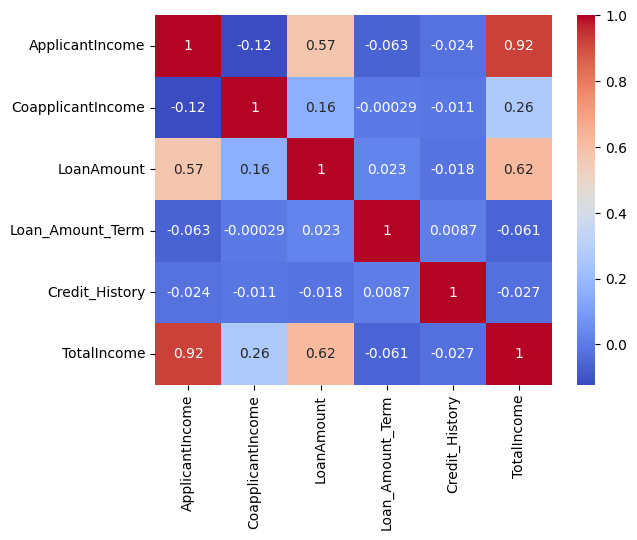

In [ ]:
cov_matrix = data.corr(numeric_only = True)
sns.heatmap(cov_matrix, cmap = 'coolwarm', annot = True)

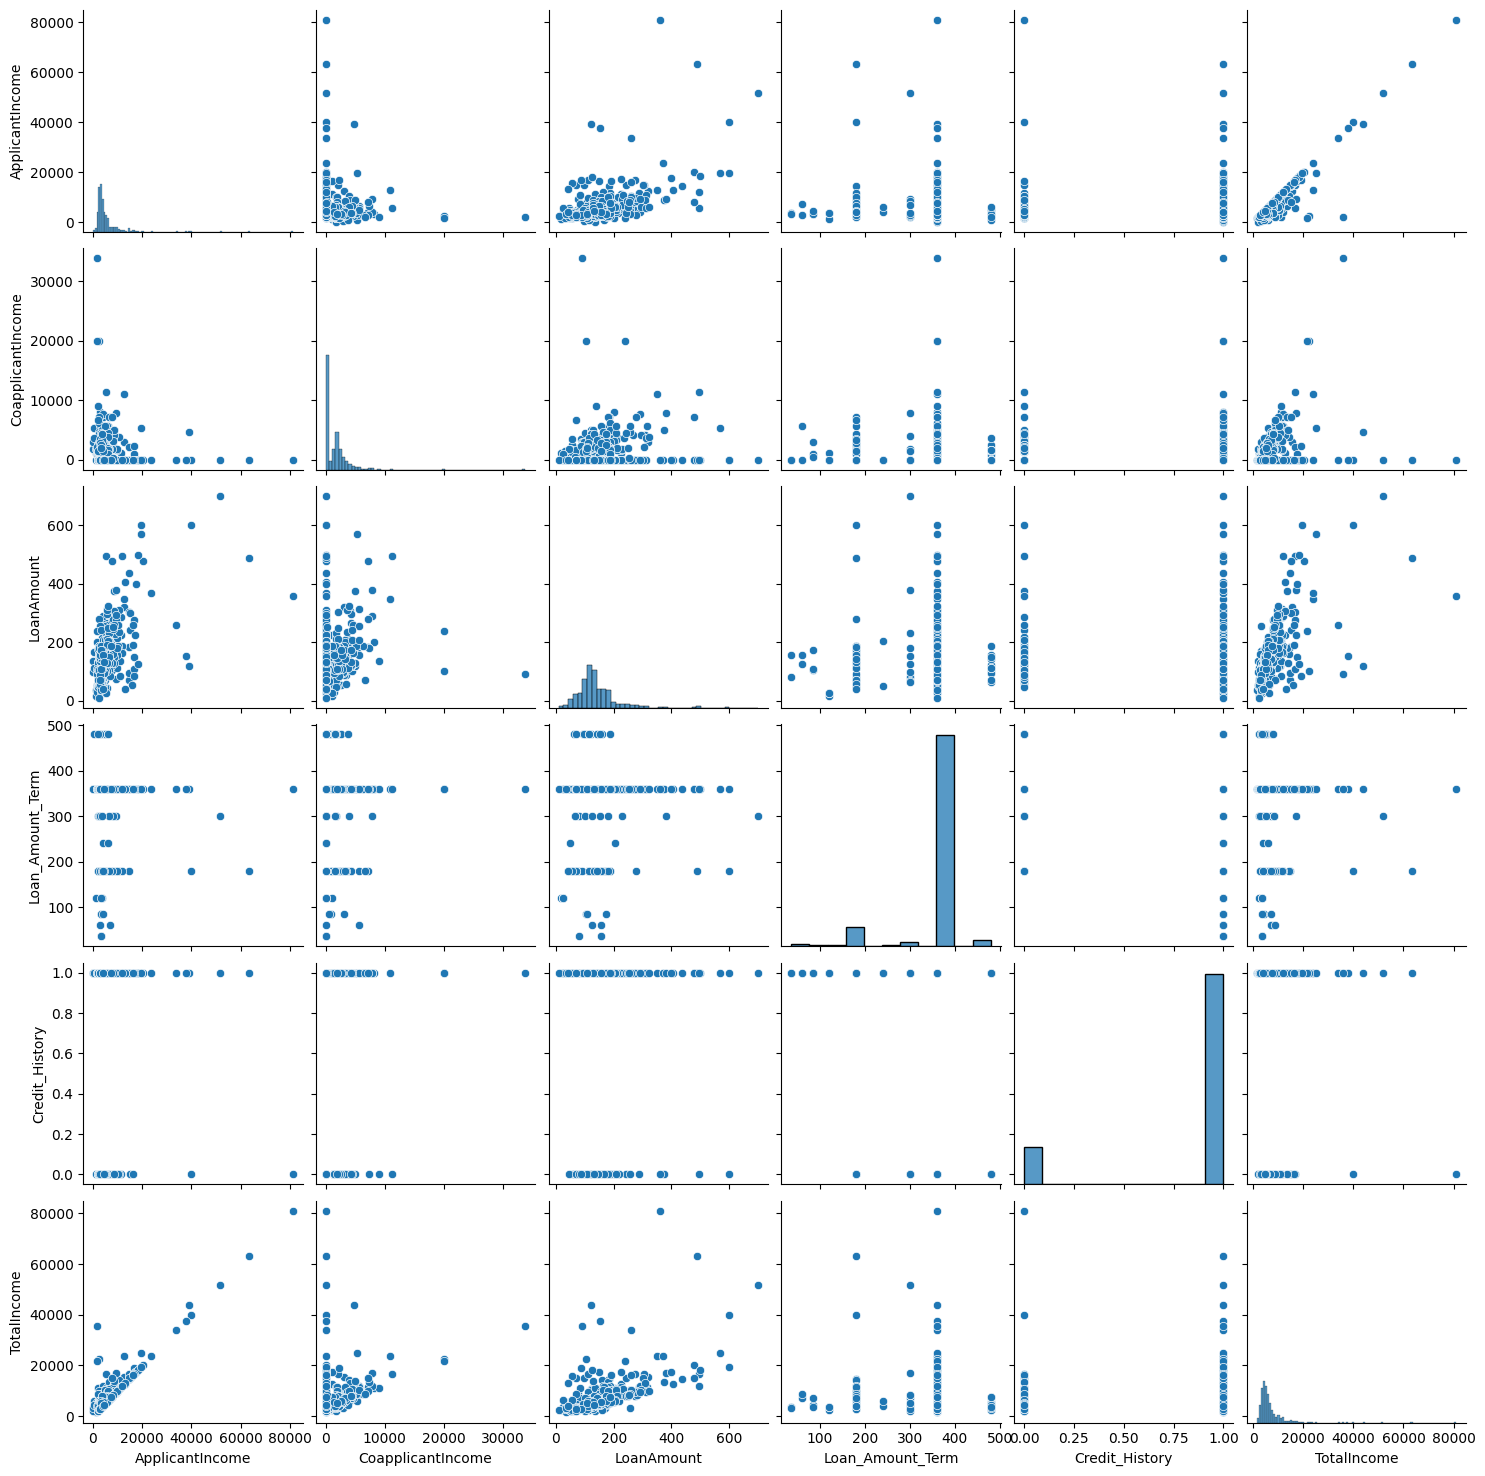

In [ ]:
sns.pairplot(data)

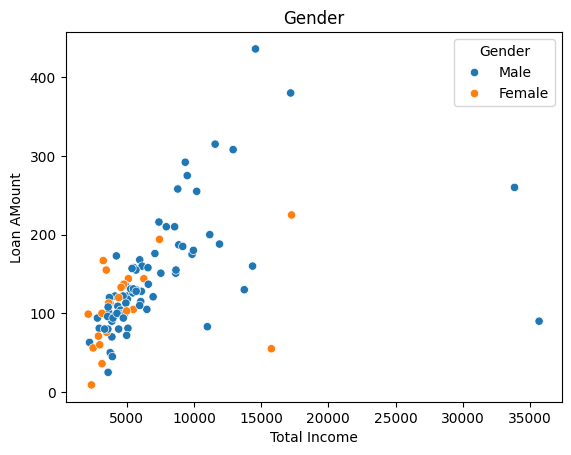

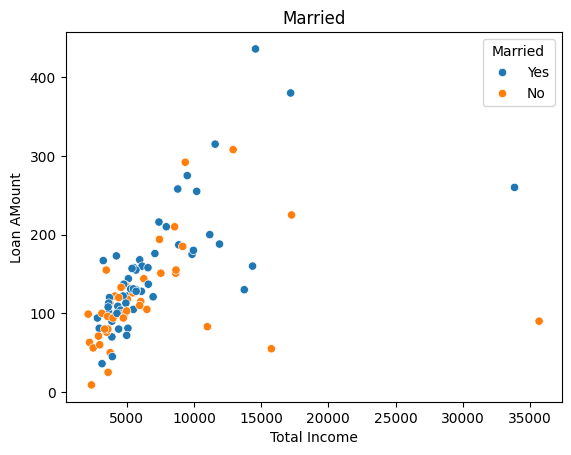

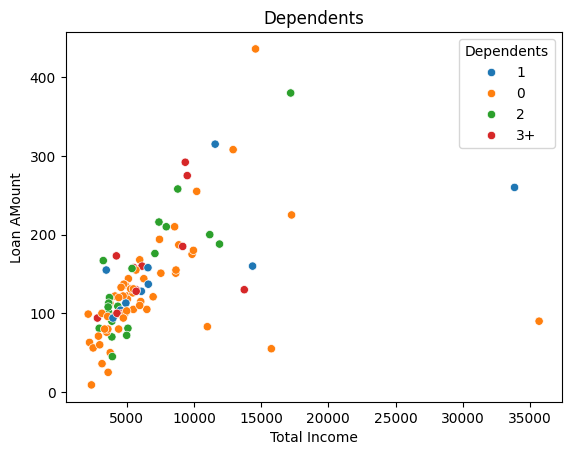

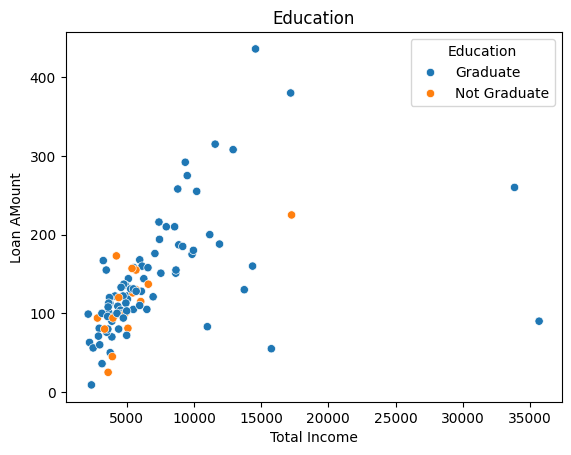

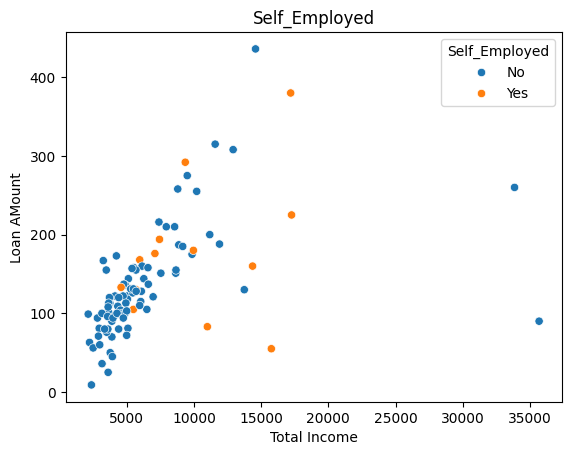

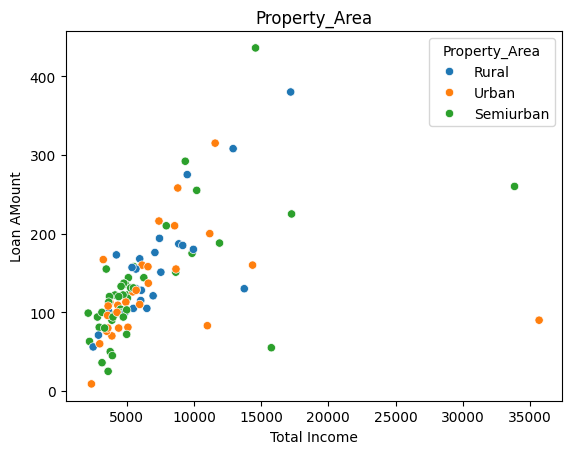

In [ ]:
for col in cat_columns:
  sns.scatterplot(x = data.TotalIncome.sample(100,random_state =42), y = data.LoanAmount.sample(100, random_state = 42), hue = data[col])
  plt.xlabel('Total Income')
  plt.ylabel('Loan AMount')
  plt.title(col)
  plt.show()


In [ ]:
from sklearn.impute import KNNImputer
imputer =  KNNImputer(n_neighbors=4)

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 614 entries, 0 to 613
Data columns (total 13 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Gender             614 non-null    object 
 1   Married            614 non-null    object 
 2   Dependents         614 non-null    object 
 3   Education          614 non-null    object 
 4   Self_Employed      614 non-null    object 
 5   ApplicantIncome    614 non-null    int64  
 6   CoapplicantIncome  614 non-null    float64
 7   LoanAmount         592 non-null    float64
 8   Loan_Amount_Term   600 non-null    float64
 9   Credit_History     564 non-null    float64
 10  Property_Area      614 non-null    object 
 11  Loan_Status        614 non-null    object 
 12  TotalIncome        614 non-null    float64
dtypes: float64(5), int64(1), object(7)
memory usage: 62.5+ KB


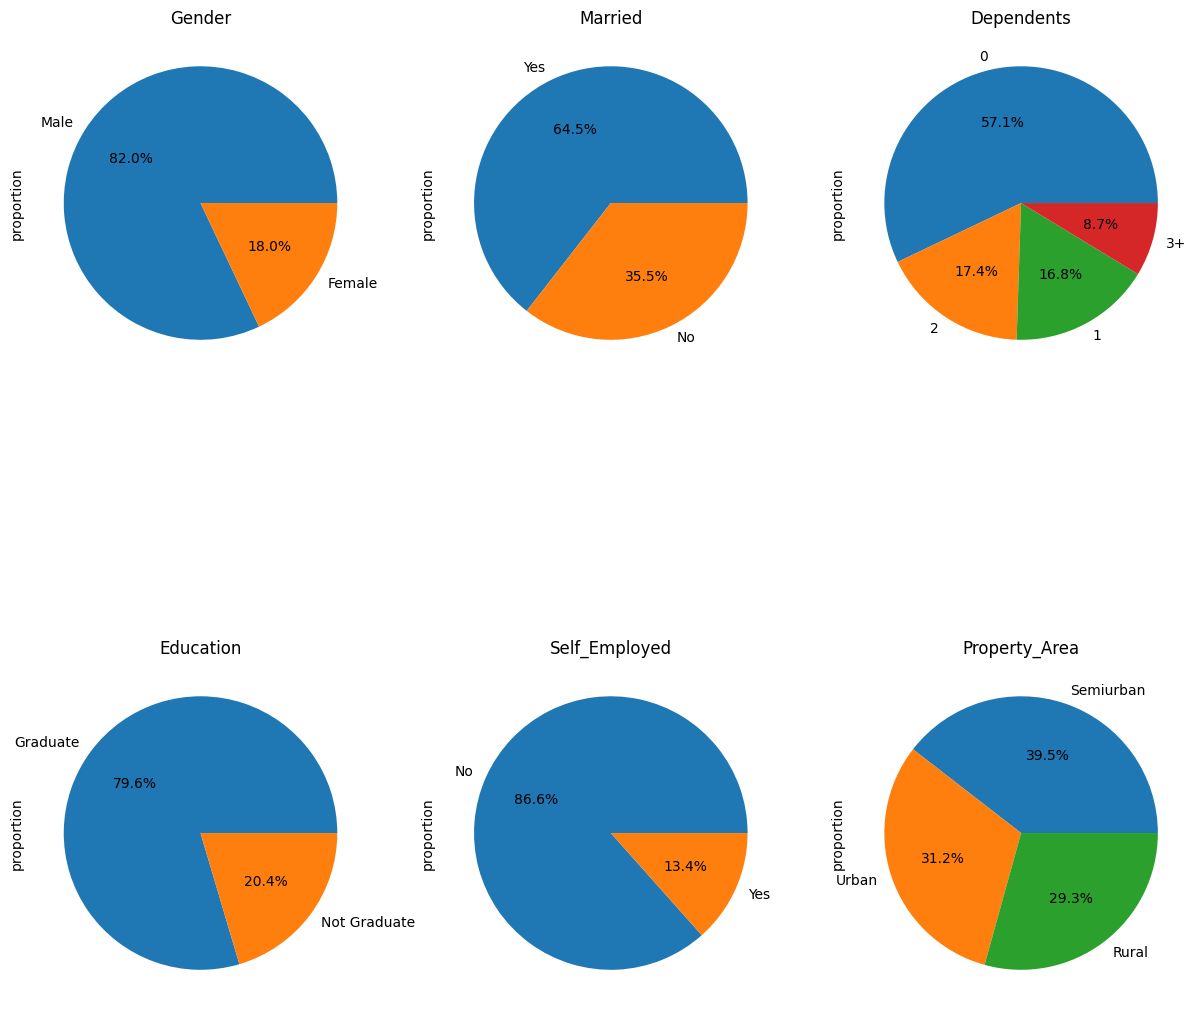

In [ ]:
# Pie chart visualization of univariate data categorical
fig, axes = plt.subplots(2,3,figsize = (15,15))
axes = axes.flatten()
i = 0
for col in cat_columns:
  data[col].value_counts(normalize = True).plot(title = col,kind = 'pie', autopct = '%1.1f%%', ax = axes[i])

  i +=1




### **OUTLIERS:**
checking and removing outliers.
methods used:
-Boxplot visualization
- IQR
-Z- score


In [ ]:
num_columns

['ApplicantIncome',
 'CoapplicantIncome',
 'LoanAmount',
 'Loan_Amount_Term',
 'Credit_History',
 'TotalIncome']

In [ ]:
from scipy.stats import zscore
outliers_income = df[abs(zscore(df.ApplicantIncome)) > 3]
outliers_income

,Gender,Married,Dependents,Education,Self_Employed,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History,Property_Area,Loan_Status,TotalIncome
126,Male,Yes,3+,Graduate,No,23803,0.0,370.0,360.0,1.0,Rural,Y,23803.0
155,Male,Yes,3+,Graduate,No,39999,0.0,600.0,180.0,0.0,Semiurban,Y,39999.0
171,Male,Yes,3+,Graduate,No,51763,0.0,700.0,300.0,1.0,Urban,Y,51763.0
183,Male,Yes,1,Graduate,No,33846,0.0,260.0,360.0,1.0,Semiurban,N,33846.0
185,Male,Yes,0,Graduate,Yes,39147,4750.0,120.0,360.0,1.0,Semiurban,Y,43897.0
333,Male,Yes,0,Graduate,No,63337,0.0,490.0,180.0,1.0,Urban,Y,63337.0
409,Male,Yes,3+,Graduate,No,81000,0.0,360.0,360.0,0.0,Rural,N,81000.0
443,Male,No,1,Graduate,No,37719,0.0,152.0,360.0,1.0,Semiurban,Y,37719.0


In [ ]:
df[abs(zscore(df.Loan_Amount_Term)) > 3] # not outliers for Loan amount term

,Gender,Married,Dependents,Education,Self_Employed,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History,Property_Area,Loan_Status,TotalIncome


In [ ]:
print(df[abs(zscore(df.CoapplicantIncome)) > 3].shape)

(6, 13)


In [ ]:
df[abs(zscore(df.LoanAmount)) > 3] # no outlier for Loan amount

,Gender,Married,Dependents,Education,Self_Employed,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History,Property_Area,Loan_Status,TotalIncome


In [ ]:
print(df[abs(zscore(df.TotalIncome)) > 3].shape)

(10, 13)


#### **Insights:**

In [ ]:
# lets try fitting model:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import Pipeline
# Converting Categorical Variables:
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder, LabelEncoder, MinMaxScaler
from sklearn.compose import ColumnTransformer
from sklearn.metrics import classification_report, accuracy_score

In [ ]:
df_try = df.dropna()
x = df_try.drop(columns = ['Loan_Status','TotalIncome'])
y = df_try.Loan_Status
x_train, x_test, y_train, y_test = train_test_split(x,y,test_size = 0.2, random_state = 35)
x_train.shape, y_train.shape, x_test.shape, y_test.shape

((423, 11), (423,), (106, 11), (106,))

In [ ]:
num_colm = [feature for feature in x.columns if x[feature].dtype!='object']
num_colm

['ApplicantIncome',
 'CoapplicantIncome',
 'LoanAmount',
 'Loan_Amount_Term',
 'Credit_History']

In [ ]:
x_train.columns

Index(['Gender', 'Married', 'Dependents', 'Education', 'Self_Employed',
       'ApplicantIncome', 'CoapplicantIncome', 'LoanAmount',
       'Loan_Amount_Term', 'Credit_History', 'Property_Area'],
      dtype='object')

In [ ]:
transformer = ColumnTransformer(transformers=[
    ('ohe', OneHotEncoder(sparse_output = False, drop = 'first'), ['Gender','Married','Self_Employed','Credit_History','Education']),
    ('oe',OrdinalEncoder(categories=[['0','1','2','3+']]), ['Dependents']),
    ('sca', MinMaxScaler(), num_colm)
])

In [ ]:
x_train_sca = transformer.fit_transform(x_train)
x_test_sca = transformer.fit_transform(x_test)

In [ ]:
le = LabelEncoder()
y_train = le.fit_transform(y_train)
y_test = le.fit_transform(y_test)

In [ ]:
logistic = LogisticRegression()
logistic.fit(x_train_sca, y_train)

LogisticRegression()

In [ ]:
logistic.score(x_test_sca, y_test)

0.839622641509434

In [ ]:
def model_report(model):
  model.fit(x_train_sca, y_train)
  y_pred = model.predict(x_test_sca)
  accuracy = round(accuracy_score(y_pred, y_test),4)

  print(f'** Reports for {model}: **')
  print('-'*35)
  print('Classification Report:')
  print(classification_report(y_pred, y_test))
  print(f'Accuracy Score: {accuracy}')
  print('='*35)

In [ ]:
logistic = LogisticRegression()
dt = DecisionTreeClassifier(max_depth = 5)
rdf = RandomForestClassifier(n_estimators = 50)
svc = SVC(C = 100, kernel = 'rbf')
knn = KNeighborsClassifier(n_neighbors = 4)
model_report(logistic)
model_report(dt)
model_report(rdf)
model_report(svc)
model_report(knn)

** Reports for LogisticRegression(): **
-----------------------------------
Classification Report:
              precision    recall  f1-score   support

           0       0.48      0.88      0.62        16
           1       0.97      0.83      0.90        90

    accuracy                           0.84       106
   macro avg       0.73      0.85      0.76       106
weighted avg       0.90      0.84      0.86       106

Accuracy Score: 0.8396
** Reports for DecisionTreeClassifier(max_depth=5): **
-----------------------------------
Classification Report:
              precision    recall  f1-score   support

           0       0.59      0.61      0.60        28
           1       0.86      0.85      0.85        78

    accuracy                           0.78       106
   macro avg       0.72      0.73      0.72       106
weighted avg       0.79      0.78      0.78       106

Accuracy Score: 0.783
** Reports for RandomForestClassifier(n_estimators=50): **
-----------------------------

In [ ]:
import tensorflow
from tensorflow import keras
from tensorflow.keras import Sequential
from tensorflow.keras.layers import Dense,Dropout,BatchNormalization


In [ ]:
model = Sequential()
model.add(Dense(64, activation = 'relu', input_dim = 11))
model.add(BatchNormalization())
model.add(Dense(32, activation = 'relu'))
model.add(BatchNormalization())
# model.add(Dropout)
model.add(Dense(16, activation = 'relu'))
model.add(BatchNormalization())
model.add(Dropout(0.5))
model.add(Dense(1, activation = 'sigmoid'))
model.summary()

/usr/local/lib/python3.11/dist-packages/keras/src/layers/core/dense.py:87: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 64)             │           768 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 64)             │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 32)             │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 16)             │            64 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 16)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,841 (15.00 KB)

 Trainable params: 3,617 (14.13 KB)

 Non-trainable params: 224 (896.00 B)

In [ ]:
model.compile(loss = 'binary_crossentropy', optimizer = 'adam',metrics = ['accuracy'])
history = model.fit(x_train_sca, y_train, epochs = 50, validation_data = (x_test_sca, y_test), verbose=0)

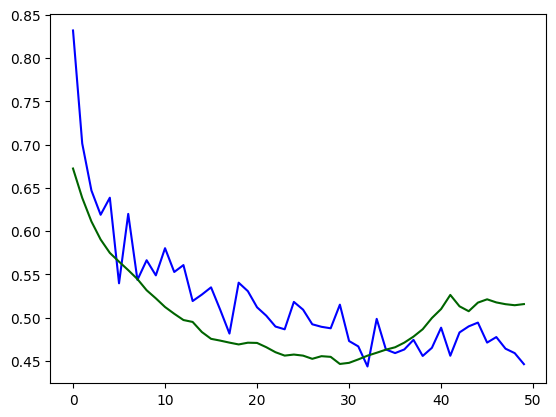

In [ ]:
plt.plot(history.history['loss'],label = 'loss',color = 'blue')
plt.plot(history.history['val_loss'], label = 'val_loss', color = 'darkgreen')
plt.show()

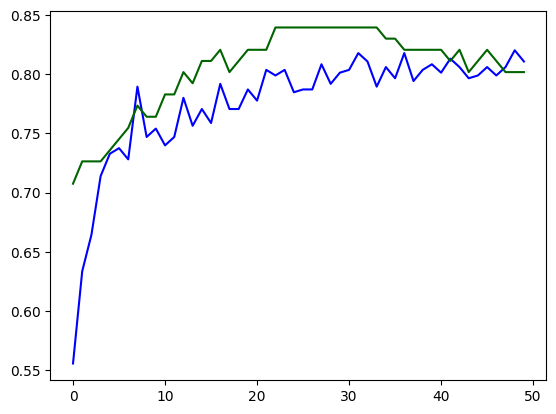

In [ ]:
plt.plot(history.history['accuracy'],label = 'accuracy',color = 'blue')
plt.plot(history.history['val_accuracy'], label = 'val_accuracy', color = 'darkgreen')
plt.show()

In [ ]:
## using robust scaling to deal with outliers in applicant income and coapplicant income
from sklearn.preprocessing import RobustScaler
transformer = ColumnTransformer(transformers=[
    ('ohe', OneHotEncoder(sparse_output = False, drop = 'first'), ['Gender','Married','Self_Employed','Credit_History','Education']),
    ('oe',OrdinalEncoder(categories=[['0','1','2','3+']]), ['Dependents']),
    ('sca', MinMaxScaler(), ['Loan_Amount_Term', 'LoanAmount']),
     ('rs', RobustScaler(), ['ApplicantIncome', 'CoapplicantIncome'])
])

In [ ]:
x_train_sca2 = transformer.fit_transform(x_train)
x_test_sca2 = transformer.fit_transform(x_test)

In [ ]:
def model_report(model):
  model.fit(x_train_sca2, y_train)
  y_pred = model.predict(x_test_sca2)
  accuracy = round(accuracy_score(y_pred, y_test),4)

  print(f'** Reports for {model}: **')
  print('-'*35)
  print('Classification Report:')
  print(classification_report(y_pred, y_test))
  print(f'Accuracy Score: {accuracy}')
  print('='*35)

In [ ]:
logistic = LogisticRegression()
dt = DecisionTreeClassifier(max_depth = 5)
rdf = RandomForestClassifier(n_estimators = 50)
svc = SVC(C = 100, kernel = 'rbf')
knn = KNeighborsClassifier(n_neighbors = 4)
model_report(logistic)
model_report(dt)
model_report(rdf)
model_report(svc)
model_report(knn)

** Reports for LogisticRegression(): **
-----------------------------------
Classification Report:
              precision    recall  f1-score   support

           0       0.48      0.82      0.61        17
           1       0.96      0.83      0.89        89

    accuracy                           0.83       106
   macro avg       0.72      0.83      0.75       106
weighted avg       0.88      0.83      0.85       106

Accuracy Score: 0.8302
** Reports for DecisionTreeClassifier(max_depth=5): **
-----------------------------------
Classification Report:
              precision    recall  f1-score   support

           0       0.55      0.64      0.59        25
           1       0.88      0.84      0.86        81

    accuracy                           0.79       106
   macro avg       0.72      0.74      0.73       106
weighted avg       0.80      0.79      0.80       106

Accuracy Score: 0.7925
** Reports for RandomForestClassifier(n_estimators=50): **
----------------------------

### accuracy increased due to robust scaling.

In [ ]:
model = Sequential()
model.add(Dense(64, activation = 'relu', input_dim = 10))
# model.add(BatchNormalization())
model.add(Dense(32, activation = 'relu'))
# model.add(BatchNormalization())
# model.add(Dropout)
model.add(Dense(16, activation = 'relu'))
# model.add(BatchNormalization())
model.add(Dropout(0.5))
model.add(Dense(1, activation = 'sigmoid'))
model.summary()

/usr/local/lib/python3.11/dist-packages/keras/src/layers/core/dense.py:87: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_4 (Dense)                 │ (None, 64)             │           704 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 16)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,329 (13.00 KB)

 Trainable params: 3,329 (13.00 KB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
model.compile(loss = 'binary_crossentropy', optimizer = 'adam',metrics = ['accuracy'])
history2 = model.fit(x_train_sca2, y_train, epochs = 40, validation_data = (x_test_sca2, y_test), verbose = 0)

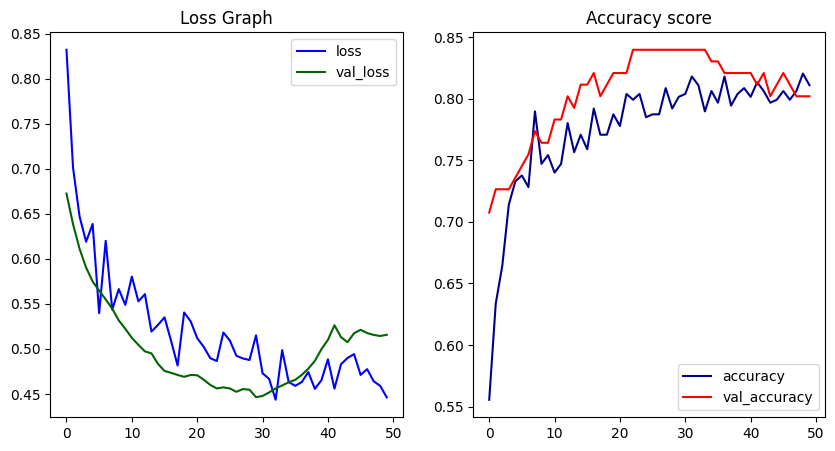

In [ ]:
plt.subplots(1,2,figsize = (10,5))
plt.subplot(121)
plt.plot(history.history['loss'],label = 'loss',color = 'blue')
plt.plot(history.history['val_loss'], label = 'val_loss', color = 'darkgreen')
plt.title('Loss Graph')
plt.legend()

plt.subplot(122)
plt.plot(history.history['accuracy'],label = 'accuracy',color = 'darkblue')
plt.plot(history.history['val_accuracy'], label = 'val_accuracy', color = 'red')
plt.title('Accuracy score')
plt.legend()
plt.show()

In [ ]:
# now let's keep total income and remove applicant and co applicant income.
df_try = df.dropna()
x = df_try.drop(columns = ['Loan_Status','ApplicantIncome', 'CoapplicantIncome'])
y = df_try.Loan_Status
x_train, x_test, y_train, y_test = train_test_split(x,y,test_size = 0.2, random_state = 35)
x_train.shape, y_train.shape, x_test.shape, y_test.shape

((423, 10), (423,), (106, 10), (106,))

In [ ]:
num_colm = [feature for feature in x.columns if x[feature].dtype!='object']
num_colm

['LoanAmount', 'Loan_Amount_Term', 'Credit_History', 'TotalIncome']

In [ ]:
transformer = ColumnTransformer(transformers=[
    ('ohe', OneHotEncoder(sparse_output = False, drop = 'first'), ['Gender','Married','Self_Employed','Credit_History','Education']),
    ('oe',OrdinalEncoder(categories=[['0','1','2','3+']]), ['Dependents']),
    ('sca', MinMaxScaler(), ['Loan_Amount_Term', 'LoanAmount']),
     ('rs', RobustScaler(), ['TotalIncome'])
])

In [ ]:
x_train_sca3 = transformer.fit_transform(x_train)
x_test_sca3 = transformer.fit_transform(x_test)

In [ ]:
le = LabelEncoder()
y_train = le.fit_transform(y_train)
y_test = le.fit_transform(y_test)

In [ ]:
#### final function, define this at the start
def model_report(model, x_train, x_test):
  model.fit(x_train, y_train)
  y_pred = model.predict(x_test)
  accuracy = round(accuracy_score(y_pred, y_test),4)

  print(f'** Reports for {model}: **')
  print('-'*35)
  print('Classification Report:')
  print(classification_report(y_pred, y_test))
  print(f'Accuracy Score: {accuracy}')
  print('='*35)

In [ ]:
logistic = LogisticRegression()
dt = DecisionTreeClassifier(max_depth = 5)
rdf = RandomForestClassifier(n_estimators = 50)
svc = SVC(C = 100, kernel = 'rbf')
knn = KNeighborsClassifier(n_neighbors = 4)
model_report(logistic, x_train_sca3, x_test_sca3)
model_report(dt, x_train_sca3, x_test_sca3)
model_report(rdf, x_train_sca3, x_test_sca3)
model_report(svc, x_train_sca3, x_test_sca3)
model_report(knn, x_train_sca3, x_test_sca3)

** Reports for LogisticRegression(): **
-----------------------------------
Classification Report:
              precision    recall  f1-score   support

           0       0.48      0.88      0.62        16
           1       0.97      0.83      0.90        90

    accuracy                           0.84       106
   macro avg       0.73      0.85      0.76       106
weighted avg       0.90      0.84      0.86       106

Accuracy Score: 0.8396
** Reports for DecisionTreeClassifier(max_depth=5): **
-----------------------------------
Classification Report:
              precision    recall  f1-score   support

           0       0.62      0.56      0.59        32
           1       0.82      0.85      0.83        74

    accuracy                           0.76       106
   macro avg       0.72      0.71      0.71       106
weighted avg       0.76      0.76      0.76       106

Accuracy Score: 0.7642
** Reports for RandomForestClassifier(n_estimators=50): **
----------------------------

In [ ]:
model = Sequential()
model.add(Dense(64, activation = 'relu', input_dim = 9))
# model.add(BatchNormalization())
model.add(Dense(32, activation = 'relu'))
# model.add(BatchNormalization())
# model.add(Dropout)
model.add(Dense(16, activation = 'relu'))
# model.add(BatchNormalization())
model.add(Dropout(0.5))
model.add(Dense(1, activation = 'sigmoid'))
model.summary()

/usr/local/lib/python3.11/dist-packages/keras/src/layers/core/dense.py:87: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_8 (Dense)                 │ (None, 64)             │           640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_9 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_10 (Dense)                │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 16)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_11 (Dense)                │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,265 (12.75 KB)

 Trainable params: 3,265 (12.75 KB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
x_test_sca3.shape

(106, 9)

In [ ]:
model.compile(loss = 'binary_crossentropy', optimizer = 'adam',metrics = ['accuracy'])
history3 = model.fit(x_train_sca3, y_train, epochs = 40, validation_data = (x_test_sca3, y_test), verbose =0)

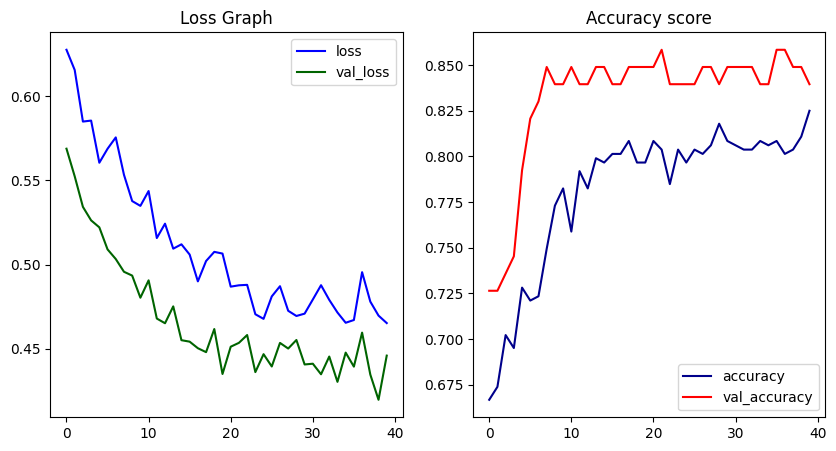

In [ ]:
plt.subplots(1,2,figsize = (10,5))
plt.subplot(121)
plt.plot(history3.history['loss'],label = 'loss',color = 'blue')
plt.plot(history3.history['val_loss'], label = 'val_loss', color = 'darkgreen')
plt.title('Loss Graph')
plt.legend()

plt.subplot(122)
plt.plot(history3.history['accuracy'],label = 'accuracy',color = 'darkblue')
plt.plot(history3.history['val_accuracy'], label = 'val_accuracy', color = 'red')
plt.title('Accuracy score')
plt.legend()
plt.show()

##**showed less improvement**

### **Idea now:**
- drop total income wala column
- let applicant income and co applicant income exits
- robust scale them.
- try to see how can we remove correlation between loan amount and applicant income.

In [ ]:
# lets check Variance Inflation factor for df:

from statsmodels.stats.outliers_influence import variance_inflation_factor

# X is your DataFrame with independent variables only
def calculate_vif(X):
    vif_data = pd.DataFrame()
    vif_data["feature"] = X.columns
    vif_data["VIF"] = [variance_inflation_factor(X.values, i)
                       for i in range(X.shape[1])]
    return vif_data



In [ ]:
x = df_try.drop(columns = cat_columns)


### trying imputation now:
- KNN imputation

In [ ]:
df.isna().sum()

,0
Gender,0
Married,0
Dependents,0
Education,0
Self_Employed,0
ApplicantIncome,0
CoapplicantIncome,0
LoanAmount,22
Loan_Amount_Term,14
Credit_History,50


##### **Loan Amount Term:**

In [ ]:
missing_indices = df[df.Loan_Amount_Term.isna()].index

yf = df_try.Loan_Amount_Term
xf = df_try.drop(columns = ['Loan_Status', 'Loan_Amount_Term', 'TotalIncome'])
xf_test = df.drop(columns = ['Loan_Status', 'Loan_Amount_Term', 'TotalIncome']).loc[missing_indices]

transformer_imp = ColumnTransformer(transformers=[
    ('ohe', OneHotEncoder(sparse_output = False, drop = 'first'), ['Gender','Married','Self_Employed','Credit_History','Education']),
    ('oe',OrdinalEncoder(categories=[['0','1','2','3+']]), ['Dependents']),
    ('sca', MinMaxScaler(), ['LoanAmount']),
     ('rs', RobustScaler(), ['ApplicantIncome', 'CoapplicantIncome'])
])

xf_train = transformer_imp.fit_transform(xf)
yf_train = np.log(yf)

from sklearn.neighbors import KNeighborsRegressor
impute_model = KNeighborsRegressor(n_neighbors = 4)
impute_model.fit(xf_train, yf_train)

yf_pred = impute_model.predict(transformer_imp.fit_transform(xf_test))
print('Imputed values value Loan AMount Term:\n',np.exp(yf_pred))

df.loc[missing_indices, 'Loan_Amount_Term'] = np.exp(yf_pred)

df.isna().sum()

Imputed values value Loan AMount Term:
 [360.         302.72270949 360.         302.72270949 254.55844123
 386.84517546 360.         360.         302.72270949 360.
 360.         360.         360.         343.95940519]


,0
Gender,0
Married,0
Dependents,0
Education,0
Self_Employed,0
ApplicantIncome,0
CoapplicantIncome,0
LoanAmount,22
Loan_Amount_Term,0
Credit_History,50


**imputing Credit History**

In [ ]:
df[df.Credit_History.isna()]

,Gender,Married,Dependents,Education,Self_Employed,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History,Property_Area,Loan_Status,TotalIncome
16,Male,No,1,Not Graduate,No,3596,0.0,100.0,240.0,NaN,Urban,Y,3596.0
24,Male,Yes,1,Graduate,No,3717,2925.0,151.0,360.0,NaN,Semiurban,N,6642.0
30,Male,Yes,1,Graduate,No,4166,3369.0,201.0,360.0,NaN,Urban,N,7535.0
42,Male,Yes,0,Graduate,No,2400,0.0,75.0,360.0,NaN,Urban,Y,2400.0
79,Male,Yes,3+,Not Graduate,Yes,3333,2166.0,130.0,360.0,NaN,Semiurban,Y,5499.0
83,Male,Yes,0,Graduate,No,6000,2250.0,265.0,360.0,NaN,Semiurban,N,8250.0
86,Male,Yes,2,Not Graduate,No,3333,2000.0,99.0,360.0,NaN,Semiurban,Y,5333.0
95,Male,No,0,Graduate,No,6782,0.0,NaN,360.0,NaN,Urban,N,6782.0
117,Male,Yes,1,Graduate,No,2214,1398.0,85.0,360.0,NaN,Urban,Y,3612.0
125,Female,No,0,Graduate,No,3692,0.0,93.0,360.0,NaN,Rural,Y,3692.0


removing row with both Loan Amount and Credit history NaN as it will cause problem in imputation using KNN.

In [ ]:
df.Credit_History.unique()

array([ 1.,  0., nan])

In [ ]:
df.drop(95, inplace = True)

**imputing credit history first**

In [ ]:
missing_indices = df[df.Credit_History.isna()].index

yf = df_try.Credit_History
xf = df_try.drop(columns = ['Loan_Status', 'Credit_History', 'TotalIncome'])

xf_test = df.drop(columns = ['Loan_Status', 'Credit_History', 'TotalIncome']).loc[missing_indices]

transformer_imp = ColumnTransformer(transformers=[
    ('ohe', OneHotEncoder(sparse_output = False, drop = 'first'), ['Gender','Married','Self_Employed','Education','Property_Area']),
    ('oe',OrdinalEncoder(categories=[['0','1','2','3+']]), ['Dependents']),
    ('sca', MinMaxScaler(), ['Loan_Amount_Term', 'LoanAmount']),
     ('rs', RobustScaler(), ['ApplicantIncome', 'CoapplicantIncome'])
])


xf_train = transformer_imp.fit_transform(xf)
yf_train = yf

impute_model = KNeighborsClassifier(n_neighbors = 4)
impute_model.fit(xf_train, yf_train)

yf_pred = impute_model.predict(transformer_imp.fit_transform(xf_test))
print('Imputed values for Credit history:\n', yf_pred)

df.loc[missing_indices, 'Credit_History'] = yf_pred

Imputed values for Credit history:
 [1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 0. 1. 1. 1. 1. 1. 1.
 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 0.
 1.]


In [ ]:
df.isna().sum()

,0
Gender,0
Married,0
Dependents,0
Education,0
Self_Employed,0
ApplicantIncome,0
CoapplicantIncome,0
LoanAmount,21
Loan_Amount_Term,0
Credit_History,0


**imputing Loan Amount**

In [ ]:
missing_indices = df[df.LoanAmount.isna()].index

yf = df_try.LoanAmount
xf = df_try.drop(columns = ['Loan_Status', 'LoanAmount', 'TotalIncome'])

xf_test = df.drop(columns = ['Loan_Status', 'LoanAmount', 'TotalIncome']).loc[missing_indices]

transformer_imp = ColumnTransformer(transformers=[
    ('ohe', OneHotEncoder(sparse_output = False, drop = 'first'), ['Gender','Married','Self_Employed','Education','Property_Area']),
    ('oe',OrdinalEncoder(categories=[['0','1','2','3+']]), ['Dependents']),
    ('sca', MinMaxScaler(), ['Loan_Amount_Term']),
     ('rs', RobustScaler(), ['ApplicantIncome', 'CoapplicantIncome'])
])


xf_train = transformer_imp.fit_transform(xf)
yf_train = np.log(yf)

impute_model = KNeighborsRegressor(n_neighbors = 4)
impute_model.fit(xf_train, yf_train)

yf_pred = impute_model.predict(transformer_imp.fit_transform(xf_test))
print('Imputed values for Loan Amount:\n', np.exp(yf_pred))

df.loc[missing_indices, 'LoanAmount'] = np.exp(yf_pred)

Imputed values for Loan Amount:
 [141.65905129 140.03683677 150.15262615 123.02185616 189.73336549
 215.40703626 111.31094788 122.57984248  72.78586782 299.30872548
  72.07713291 129.76403744 143.67819139 123.45541749 216.22537481
 106.21936218 146.99808962 185.75936582 139.03024005 129.09882003
 118.76088719]


In [ ]:
df.isna().sum()

,0
Gender,0
Married,0
Dependents,0
Education,0
Self_Employed,0
ApplicantIncome,0
CoapplicantIncome,0
LoanAmount,0
Loan_Amount_Term,0
Credit_History,0


### **now fitting models and checking accuracy scores**

<Axes: xlabel='LoanAmount', ylabel='Count'>

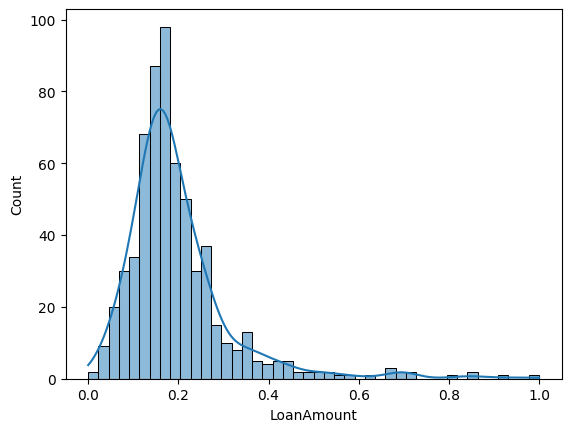

In [ ]:
min_max = (df.LoanAmount - np.min(df.LoanAmount))/(np.max(df.LoanAmount) - np.min(df.LoanAmount))
sns.histplot(min_max, kde = True)

#### **requires standardization in place of normalization**

In [ ]:
from sklearn.preprocessing import StandardScaler

In [ ]:
transformer = ColumnTransformer(transformers=[
    ('ohe', OneHotEncoder(sparse_output = False, drop = 'first'), ['Gender','Married','Self_Employed','Credit_History','Education']),
    ('oe',OrdinalEncoder(categories=[['0','1','2','3+']]), ['Dependents']),
    ('sca', StandardScaler(), ['Loan_Amount_Term', 'LoanAmount']),
     ('rs', RobustScaler(), ['CoapplicantIncome', 'ApplicantIncome'])
])

In [ ]:
x = df.drop(columns = ['Loan_Status','TotalIncome'])
y = df.Loan_Status

In [ ]:
x = transformer.fit_transform(x)

In [ ]:
y = le.fit_transform(y)

In [ ]:
x_train, x_test, y_train, y_test = train_test_split(x,y, test_size = 0.2, random_state = 35)

In [ ]:
logistic = LogisticRegression()
dt = DecisionTreeClassifier(max_depth = 5)
rdf = RandomForestClassifier(n_estimators = 50)
svc = SVC(C = 100, kernel = 'rbf')
knn = KNeighborsClassifier(n_neighbors = 4)
model_report(logistic, x_train, x_test)
model_report(dt,x_train, x_test)
model_report(rdf,x_train, x_test)
model_report(svc,x_train, x_test)
model_report(knn,x_train, x_test)

** Reports for LogisticRegression(): **
-----------------------------------
Classification Report:
              precision    recall  f1-score   support

           0       0.35      1.00      0.52        11
           1       1.00      0.82      0.90       112

    accuracy                           0.84       123
   macro avg       0.68      0.91      0.71       123
weighted avg       0.94      0.84      0.87       123

Accuracy Score: 0.8374
** Reports for DecisionTreeClassifier(max_depth=5): **
-----------------------------------
Classification Report:
              precision    recall  f1-score   support

           0       0.42      0.81      0.55        16
           1       0.97      0.83      0.89       107

    accuracy                           0.83       123
   macro avg       0.69      0.82      0.72       123
weighted avg       0.90      0.83      0.85       123

Accuracy Score: 0.8293
** Reports for RandomForestClassifier(n_estimators=50): **
----------------------------

<Axes: xlabel='LoanAmount', ylabel='Count'>

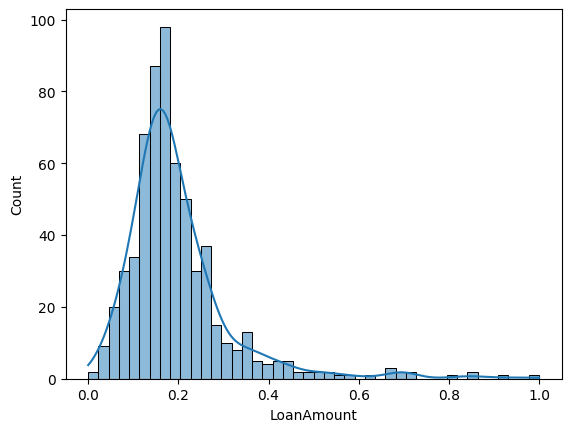

In [ ]:
min_max = (df.LoanAmount - np.min(df.LoanAmount))/(np.max(df.LoanAmount) - np.min(df.LoanAmount))
sns.histplot(min_max, kde = True)

In [ ]:
from imblearn.over_sampling import SMOTE
smote = SMOTE(random_state = 35)

In [ ]:
x_train_res, y_train_res = smote.fit_resample(x_train, y_train)

In [ ]:
print("1:", y_test.sum())
print('0:', y_test.size - y_test.sum())


1: 92
0: 31


In [ ]:
#### final function, define this at the start
def model_report(model, x_train, x_test):
  model.fit(x_train, y_train_res)
  y_pred = model.predict(x_test)
  accuracy = round(accuracy_score(y_pred, y_test),4)

  print(f'** Reports for {model}: **')
  print('-'*35)
  print('Classification Report:')
  print(classification_report(y_pred, y_test))
  print(f'Accuracy Score: {accuracy}')
  print('Confusion Matrix:\n', confusion_matrix(y_test, y_pred))
  print('='*35)

In [ ]:
from sklearn.metrics import confusion_matrix
logistic = LogisticRegression()
dt = DecisionTreeClassifier(max_depth = 5)
rdf = RandomForestClassifier(n_estimators = 50)
svc = SVC(C = 100, kernel = 'rbf')
knn = KNeighborsClassifier(n_neighbors = 4)
model_report(logistic, x_train_res, x_test)
model_report(dt,x_train_res, x_test)
model_report(rdf,x_train_res, x_test)
model_report(svc,x_train_res, x_test)
model_report(knn,x_train_res, x_test)

** Reports for LogisticRegression(): **
-----------------------------------
Classification Report:
              precision    recall  f1-score   support

           0       0.35      1.00      0.52        11
           1       1.00      0.82      0.90       112

    accuracy                           0.84       123
   macro avg       0.68      0.91      0.71       123
weighted avg       0.94      0.84      0.87       123

Accuracy Score: 0.8374
Confusion Matrix:
 [[11 20]
 [ 0 92]]
** Reports for DecisionTreeClassifier(max_depth=5): **
-----------------------------------
Classification Report:
              precision    recall  f1-score   support

           0       0.39      0.92      0.55        13
           1       0.99      0.83      0.90       110

    accuracy                           0.84       123
   macro avg       0.69      0.88      0.72       123
weighted avg       0.93      0.84      0.86       123

Accuracy Score: 0.8374
Confusion Matrix:
 [[12 19]
 [ 1 91]]
** Reports 

In [ ]:
x_train_res.shape

In [ ]:
model = Sequential()
model.add(Dense(64, activation = 'relu', input_dim = 10))
# model.add(BatchNormalization())
model.add(Dense(32, activation = 'relu'))
# model.add(BatchNormalization())
model.add(Dropout(0.25))
model.add(Dense(16, activation = 'relu'))
# model.add(BatchNormalization())
model.add(Dropout(0.5))
model.add(Dense(1, activation = 'sigmoid'))
model.summary()

model.compile(loss = 'binary_crossentropy', optimizer = 'adam',metrics = ['accuracy'])
history = model.fit(x_train_res, y_train_res, epochs = 50, validation_data = (x_test, y_test), verbose =1)

plt.subplots(1,2,figsize = (10,5))
plt.subplot(121)
plt.plot(history.history['loss'],label = 'loss',color = 'blue')
plt.plot(history.history['val_loss'], label = 'val_loss', color = 'darkgreen')
plt.title('Loss Graph')
plt.legend()

plt.subplot(122)
plt.plot(history.history['accuracy'],label = 'accuracy',color = 'darkblue')
plt.plot(history.history['val_accuracy'], label = 'val_accuracy', color = 'red')
plt.title('Accuracy score')
plt.legend()
plt.show()

### **Gaussian Naive Bayes**

In [ ]:
from sklearn.naive_bayes import GaussianNB
gaussian = GaussianNB()
model_report(gaussian, x_train_res, x_test)

#### ek baari mein it went close to the max of random forest after hypertuning.

#### **Hypertuning Parameters**

In [ ]:
from sklearn.model_selection import GridSearchCV

**Random Forest Classifier**

In [ ]:
params = {
    'max_depth': [3,4,5,6,7],
    'min_samples_split': [4,5,6,7,8],
    'min_samples_leaf': [3,5,7,8],
    'n_estimators': [40,50,60,70,80]
}

In [ ]:
rfc = RandomForestClassifier()
grid = GridSearchCV(rfc, param_grid = params, cv = 5, scoring = 'accuracy')
grid.fit(x_train_res, y_train_res)

In [ ]:
print(grid.best_score_)
print(grid.best_params_)

In [ ]:
model = RandomForestClassifier(max_depth = 7, min_samples_leaf = 3, n_estimators = 70, min_samples_split = 4)
model_report(model, x_train_res, x_test)

### enhanced accuracy by **3.2%**

**Support Vector Machine**

In [ ]:
svc = SVC()

param_grid = {
    'C': [0.1, 1, 10, 100],
    'kernel': ['poly'],
    'degree': [2, 3, 4],
    'gamma': ['scale', 'auto', 0.01, 0.1, 1],
    'coef0': [0, 0.5]
}

grid_search = GridSearchCV(svc, param_grid, cv=5, scoring='accuracy')

grid_search.fit(x_train_res, y_train_res)

print("Best Parameters:", grid_search.best_params_)
print("Best Score:", grid_search.best_score_)

In [ ]:
svc = SVC(C= 1, kernel = 'poly', gamma = 1, degree = 4, coef0 = 0)
model_report(svc, x_train_res, x_test)

In [ ]:
svc = SVC(C= 10, kernel = 'linear', gamma = 0.1, degree = 4, coef0 = 0.5)
model_report(svc, x_train_res, x_test)

**it gives overall better results from random forest best model.**

Working with logistic regression models

In [ ]:
logistic = LogisticRegression(penalty = 'l2')
model_report(logistic, x_train_res, x_test)

**Bootstrapping with logistic as base model**

In [ ]:
from sklearn.ensemble import BaggingClassifier

base_model = SVC(C =10 , kernel = 'linear')

bagging_model = BaggingClassifier(
    estimator=base_model,
    n_estimators=50,          # number of bootstrap samples/models
    max_samples=0.8,          # fraction of samples for each bootstrap
    bootstrap=True ,          # enable bootstrap sampling
    n_jobs = -1              # utilize all cores

)

model_report(bagging_model, x_train_res, x_test)